config.json:   0%|          | 0.00/6.57k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  375MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

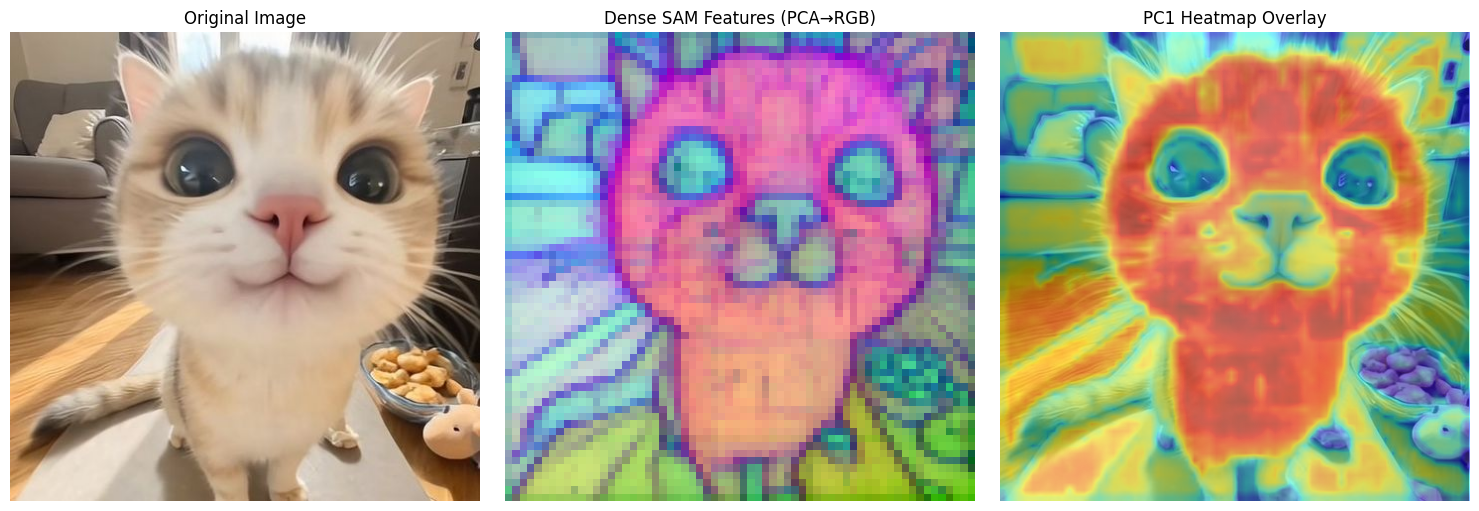

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from transformers import SamModel, SamProcessor
from PIL import Image

# --- 1. Extract dense features with SAM ---
model_name = "facebook/sam-vit-base"  # or "facebook/sam-vit-large", "facebook/sam-vit-base"
model = SamModel.from_pretrained(model_name).eval()
processor = SamProcessor.from_pretrained(model_name)

image = Image.open("/content/5da360c98b9af0ad709fe18606992229.jpg").convert("RGB")
inputs = processor(images=image, return_tensors="pt")

with torch.no_grad():
    # SAM's vision encoder returns neck features by default: [B, 256, 64, 64]
    # output_hidden_states=True gives us the last transformer layer BEFORE the neck
    # which is higher-dimensional and more analogous to RADIO patch tokens.
    vision_outputs = model.vision_encoder(
        inputs["pixel_values"],
        output_hidden_states=True,
    )
    # Last transformer layer output (pre-neck): [B, N, D]
    features = vision_outputs.hidden_states[-1]

# Reshape to spatial grid. SAM uses patch_size=16 on 1024x1024 -> 64x64 grid.
if features.dim() == 3:
    B, N, D = features.shape
    grid_h = grid_w = int(np.sqrt(N))
    features_np = features[0].numpy()  # [N, D]
elif features.dim() == 4:
    B, H, W, D = features.shape
    grid_h, grid_w = H, W
    features_np = features[0].reshape(-1, D).numpy()
else:
    raise ValueError(f"Unexpected feature shape: {features.shape}")

# --- 2. PCA to 3 components -> pseudo-RGB ---
pca = PCA(n_components=3)
pca_features = pca.fit_transform(features_np)  # [N, 3]

pca_features_norm = (pca_features - pca_features.min(axis=0)) / (
    pca_features.max(axis=0) - pca_features.min(axis=0) + 1e-8
)

pca_image = pca_features_norm.reshape(grid_h, grid_w, 3)

# --- 3. Plot: original image, PCA-RGB map, and single-component heatmap ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(pca_image)
axes[1].set_title("Dense SAM Features (PCA→RGB)")
axes[1].axis("off")

pca1 = pca_features_norm[:, 0].reshape(grid_h, grid_w)
axes[2].imshow(image)
axes[2].imshow(
    pca1,
    cmap="jet",
    alpha=0.5,
    extent=(0, image.width, image.height, 0),
    interpolation="bilinear",
)
axes[2].set_title("PC1 Heatmap Overlay")
axes[2].axis("off")

plt.tight_layout()
plt.savefig("sam_dense_features.png", dpi=150)
plt.show()